# HBC labels Data

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import os
import random
from sklearn.metrics import adjusted_rand_score

import scSLAT
from scSLAT.model import Cal_Spatial_Net, load_anndatas, run_SLAT, spatial_match
from scSLAT.viz import match_3D_multi, hist, Sankey

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [2]:
# load Merfish mouse brain 33 data
file_path = '/pkl_data/xenium_rep1_io_aligned.h5'
file_path2 = '/pkl_data/xenium_rep2_io_aligned.h5'

ad = sc.read(file_path)
ad_target = sc.read(file_path2)

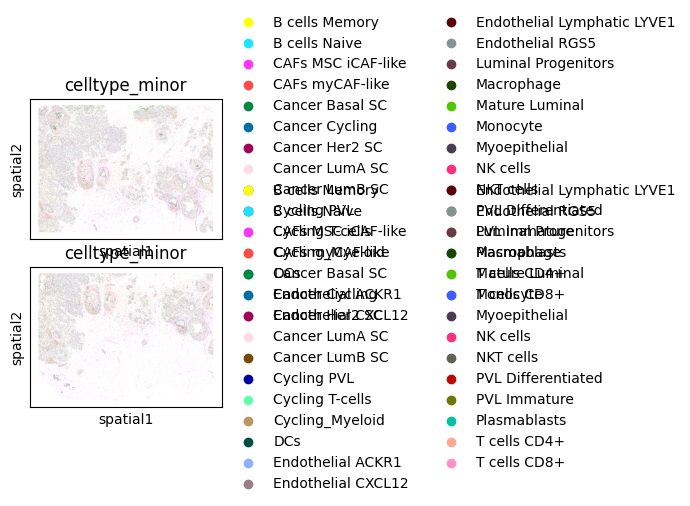

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(6, 4))
sc.pl.spatial(ad, color='celltype_minor', spot_size=5, ax=axes[0], show=False)
sc.pl.spatial(ad_target, color='celltype_minor', spot_size=5, ax=axes[1], show=False)
plt.show()

In [4]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)  # If using multi-GPU
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False  # May slow down training


def cal_laa_ari(ad_df):
    true_clusters_mapped_region = []  # Define lists inside the function
    mapped_clusters_mapped_region = []
    cnt = 0  
    
    for i in range(len(ad_df)):
        f1_cluster = ad_df.iloc[i]['target_celltype']
        f2_cluster = ad_df.iloc[i]['celltype']
        true_clusters_mapped_region.append(f1_cluster)
        mapped_clusters_mapped_region.append(f2_cluster)
        if f1_cluster == f2_cluster:
            cnt += 1 

    laa = cnt/len(ad_df)
    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
              
    return laa,ari

In [5]:
seeds_to_run = [2024, 1, 2, 3, 4, 10, 11, 12, 13, 14]

# seeds_to_run = [2024, 1]

for seed in seeds_to_run:
    print('--------------'+ str(seed))
    set_seed(seed)
    
    # Calculating spatial neighbor graph
    Cal_Spatial_Net(ad_target, k_cutoff=10, model='KNN')
    Cal_Spatial_Net(ad, k_cutoff=10, model='KNN')
    
    # Use DPCA feature to format graph
    edges, features = load_anndatas([ad_target, ad], feature='PCA', check_order=False)
    embd0, embd1, time = run_SLAT(features, edges)
    best, index, distance = spatial_match([embd0, embd1], adatas=[ad_target, ad], reorder=False)
    
    ad_target_df = pd.DataFrame({'index': range(embd0.shape[0]),
                            'x': ad_target.obsm['spatial'][:,0],
                            'y': ad_target.obsm['spatial'][:,1],
                            'celltype': ad_target.obs['celltype_minor']})
    ad_df = pd.DataFrame({'index': range(embd1.shape[0]),
                            'x': ad.obsm['spatial'][:,0],
                            'y': ad.obsm['spatial'][:,1],
                            'celltype': ad.obs['celltype_minor']})

    matching = np.array([range(index.shape[0]), best])
    best_match = distance[:,0]

    ad_df['target_index'] = best
    ad_df['target_celltype'] = ad_target_df.iloc[matching[1,:],:]['celltype'].to_list()
    ad_df['cos_similarity'] = best_match
    
    ad_df.to_csv(f'/pkl_data/{seed}/xenium_rep1.csv', index=False)
    
    laa,ari = cal_laa_ari(ad_df)
    print(f'LAA: {laa}')
    print(f'ARI: {ari}')
    
    column = 'rep1_rep2'
    filename = 'xenium_rep1_rep2_ARI.csv'
    excel_path = f'/pkl_data/{seed}/{filename}'
    # Check if the file exists
    if not os.path.exists(excel_path):
        # Define the header and first row
        header = [' ', 'rep1_rep2']
        first_row = [[0, ari]]  # First column is 0, others are empty

        # Create a DataFrame
        df = pd.DataFrame(first_row, columns=header)
        print(df)
        # Save as a CSV file
        df.to_csv(excel_path, index=False)
        
    filename = 'xenium_rep1_rep2_LAA.csv'
    excel_path = f'/pkl_data/{seed}/{filename}'
    # Check if the file exists
    if not os.path.exists(excel_path):
        # Define the header and first row
        header = [' ', 'rep1_rep2']
        first_row = [[0, laa,]]  # First column is 0, others are empty

        # Create a DataFrame
        df = pd.DataFrame(first_row, columns=header)
        print(df)
        # Save as a CSV file
        df.to_csv(excel_path, index=False)
        
    filename = 'xenium_rep1_rep2_RunTime.xlsx'
    excel_path = f'/pkl_data/{seed}/{filename}'
    # Check if the file exists
    if not os.path.exists(excel_path):
        # Define the header and first row
        header = [' ', 'rep1_rep2']
        first_row = [[0, time]]  # First column is 0, others are empty

        # Create a DataFrame
        df = pd.DataFrame(first_row, columns=header)
        print(df)
        # Save as a CSV file
        df.to_excel(excel_path, index=False)

--------------2024
Calculating spatial neighbor graph ...
The graph contains 1334338 edges, 118752 cells.
11.236341282673134 neighbors per cell on average.
Calculating spatial neighbor graph ...
The graph contains 1875722 edges, 167780 cells.
11.179651925140064 neighbors per cell on average.
Use PCA feature to format graph
All genes are highly variable.
Choose GPU:0 as device
Running
Training model time: 25.56
LAA: 0.4559244248420551
ARI: 0.26284195943986677
      rep1_rep2
0  0   0.262842
      rep1_rep2
0  0   0.455924
      rep1_rep2
0  0  25.560516
--------------1
Calculating spatial neighbor graph ...
The graph contains 1334338 edges, 118752 cells.
11.236341282673134 neighbors per cell on average.
Calculating spatial neighbor graph ...
The graph contains 1875722 edges, 167780 cells.
11.179651925140064 neighbors per cell on average.
Use PCA feature to format graph
All genes are highly variable.
Choose GPU:0 as device
Running
Training model time: 25.12
LAA: 0.4541244486827989
ARI: 0